# Anotação e ruído de rótulos

Vamos analisar as anotações do `pvd_images`: medir a concordância entre os anotadores, procurar
viés e usar um classificador para montar uma fila de imagens com rótulo suspeito.

In [17]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

def load_rgb(path):
    """Abre qualquer imagem do conjunto e devolve um RGB de 8 bits. Essa função foi implementada
    em um notebook anterior."""
    with Image.open(path) as image:
        image = ImageOps.exif_transpose(image)
        if image.mode in ("RGBA", "LA") or "transparency" in image.info:
            image = image.convert("RGBA")
            background = Image.new("RGBA", image.size, (255, 255, 255, 255))
            image = Image.alpha_composite(background, image)
        return image.convert("RGB")

def plot_matrix(matrix, fmt=".2f", cmap="Blues"):
    """Mostra um DataFrame como mapa de calor, com o valor escrito em cada célula."""
    fig, ax = plt.subplots(figsize=(0.7*matrix.shape[1] + 2, 0.5*matrix.shape[0] + 1))
    ax.imshow(matrix.to_numpy(), cmap=cmap, aspect="auto")
    for row in range(matrix.shape[0]):
        for column in range(matrix.shape[1]):
            value = matrix.iloc[row, column]
            ax.text(column, row, format(value, fmt), ha="center", va="center", fontsize=8,
                    bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.6, "pad": 1})
    ax.set_xticks(range(matrix.shape[1]))
    ax.set_xticklabels(matrix.columns, rotation=45, ha="right")
    ax.set_yticks(range(matrix.shape[0]))
    ax.set_yticklabels(matrix.index)
    fig.tight_layout()
    plt.show()

def normalize_rows(features):
    """Divide cada linha pelo seu comprimento, para que todos os vetores tenham norma 1."""
    norms = np.linalg.norm(features, axis=1, keepdims=True)
    return features / norms

## Os arquivos de anotação

- `annotations.csv` tem uma linha por anotação
- `labels_consensus.csv` tem o rótulo final de cada imagem

In [18]:
# Altere para o caminho do seu sistema
dataset_dir = Path("../dados/pvd_images")

annotations = pd.read_csv(dataset_dir / "annotations.csv")
consensus = pd.read_csv(dataset_dir / "labels_consensus.csv")

annotations.head(10)

,image_name,annotator_id,annotation_round,annotator_label,annotator_class_name,annotation_seconds,annotation_index
0,002g3.jpeg,A1,producao,3,water jug,20.1,303
1,008uh.jpeg,A1,calibracao,5,folding chair,9.1,0
2,008uh.jpeg,A2,calibracao,5,folding chair,6.1,0
3,008uh.jpeg,A3,calibracao,4,park bench,13.2,0
4,008uh.jpeg,A4,calibracao,5,folding chair,1.8,0
5,008uh.jpeg,A5,calibracao,5,folding chair,8.6,0
6,00a0u.jpeg,A2,producao,6,dining table,4.8,576
7,00xjm.jpeg,A1,calibracao,4,park bench,27.2,1
8,00xjm.jpeg,A2,calibracao,4,park bench,9.2,1
9,00xjm.jpeg,A3,calibracao,4,park bench,0.5,1


In [19]:
consensus.head()

,image_name,class_label,class_name,n_annotators,n_agreeing,agreement_ratio,resolution_method,annotation_round
0,002g3.jpeg,3,water jug,1,1,1.0,anotador_unico,producao
1,008uh.jpeg,5,folding chair,5,4,0.8,maioria,calibracao
2,00a0u.jpeg,6,dining table,1,1,1.0,anotador_unico,producao
3,00xjm.jpeg,4,park bench,5,5,1.0,unanimidade,calibracao
4,0132a.jpeg,6,dining table,1,1,1.0,anotador_unico,producao


In [20]:
# Nome de cada classe, na ordem dos rótulos de 0 a 8
classes = consensus[["class_label", "class_name"]].drop_duplicates().sort_values("class_label")
class_names = list(classes["class_name"])
n_classes = len(class_names)

print(class_names)

['coffee mug', 'cup', 'pitcher', 'water jug', 'park bench', 'folding chair', 'dining table', 'sports car', 'other']


## Tabela imagem x anotador

Para comparar os anotadores precisamos das imagens que **todos** viram, que são as da rodada de
calibração. O `pivot` coloca uma imagem por linha e um anotador por coluna.

In [21]:
def per_image_annotations(annotations):
    """Tabela com uma imagem por linha e um anotador por coluna. Cada valor é o rótulo dado."""
    selected = annotations[annotations["annotation_round"] == "calibracao"]
    return selected.pivot(index="image_name", columns="annotator_id", values="annotator_label")

image_ann = per_image_annotations(annotations)

print(image_ann.shape)
image_ann.head()

(300, 5)


annotator_id,A1,A2,A3,A4,A5
image_name,,,,,
008uh.jpeg,5,5,4,5,5
00xjm.jpeg,4,4,4,4,4
05hhi.jpeg,3,3,3,0,3
0a4ab.jpeg,2,3,2,2,2
0axyc.jpeg,1,1,1,1,1


## Concordância entre dois anotadores

Usaremos a função `cohen_kappa_score` do módulo `sklearn.metrics` para calcular o coeficiente de Kappa de Cohen. 

In [22]:
from sklearn.metrics import cohen_kappa_score

print(f"sklearn: {cohen_kappa_score(image_ann['A1'], image_ann['A2']):.3f}")

sklearn: 0.857


Agora o κ entre todos os pares de anotadores.

In [23]:
def cohen_kappa_matrix(image_ann):
    """Kappa de Cohen entre cada par de colunas (anotadores) da tabela."""
    annotator_ids = list(image_ann.columns)
    matrix = pd.DataFrame(1.0, index=annotator_ids, columns=annotator_ids)
    for first in annotator_ids:
        for second in annotator_ids:
            if first != second:
                matrix.loc[first, second] = cohen_kappa_score(image_ann[first], image_ann[second])
    return matrix


kappa_matrix = cohen_kappa_matrix(image_ann)
kappa_matrix.round(2)

,A1,A2,A3,A4,A5
A1,1.00,0.86,0.82,0.72,0.75
A2,0.86,1.00,0.74,0.67,0.73
A3,0.82,0.74,1.00,0.63,0.67
A4,0.72,0.67,0.63,1.00,0.60
A5,0.75,0.73,0.67,0.60,1.00


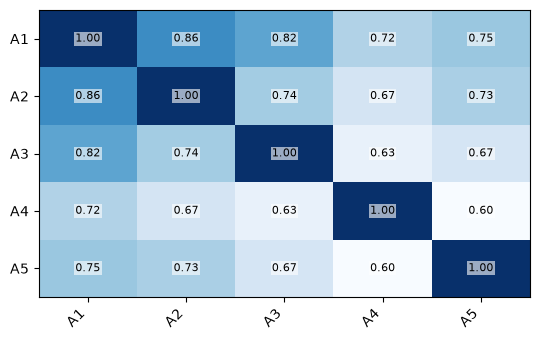

In [24]:
plot_matrix(kappa_matrix)

## Viés de anotadores

Não temos o rótulo verdadeiro, então comparamos cada anotador com a **maioria dos outros
quatro**. Uma célula grande fora da diagonal indica um erro que se repete na mesma direção.

In [25]:
def count_votes(image_ann, n_classes):
    """Matriz em que a posição (i, j) é quantos anotadores deram a classe j para a imagem i."""
    counts = np.zeros((len(image_ann), n_classes), dtype=int)
    for row, votes in enumerate(image_ann.to_numpy()):
        for label in votes:
            counts[row, label] += 1
    return counts

counts = count_votes(image_ann, n_classes)

# As cinco primeiras imagens. Cada linha soma 5, o número de anotadores.
counts[:5]

array([[0, 0, 0, 0, 1, 4, 0, 0, 0],
       [0, 0, 0, 0, 5, 0, 0, 0, 0],
       [1, 0, 0, 4, 0, 0, 0, 0, 0],
       [0, 0, 4, 1, 0, 0, 0, 0, 0],
       [0, 5, 0, 0, 0, 0, 0, 0, 0]])

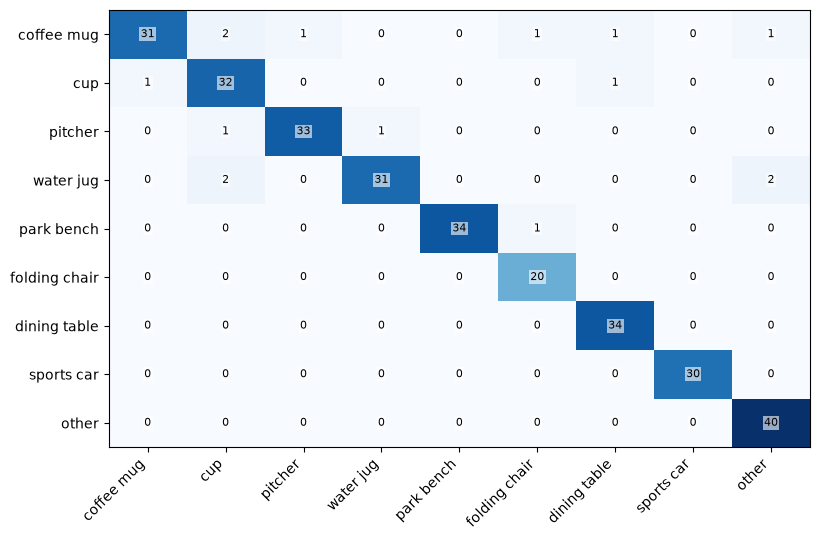

In [26]:
def annotator_confusion(image_ann, annotator_id, class_names):
    """Matriz de confusão de um anotador contra a maioria dos demais."""
    others = image_ann.drop(columns=annotator_id)

    # Classe definida pela maioria dos outros anotadores. 
    reference = count_votes(others, len(class_names)).argmax(axis=1)
    table = pd.crosstab(reference, image_ann[annotator_id])

    table.index = class_names
    table.columns = class_names
    return table


plot_matrix(annotator_confusion(image_ann, "A1", class_names), fmt="d")

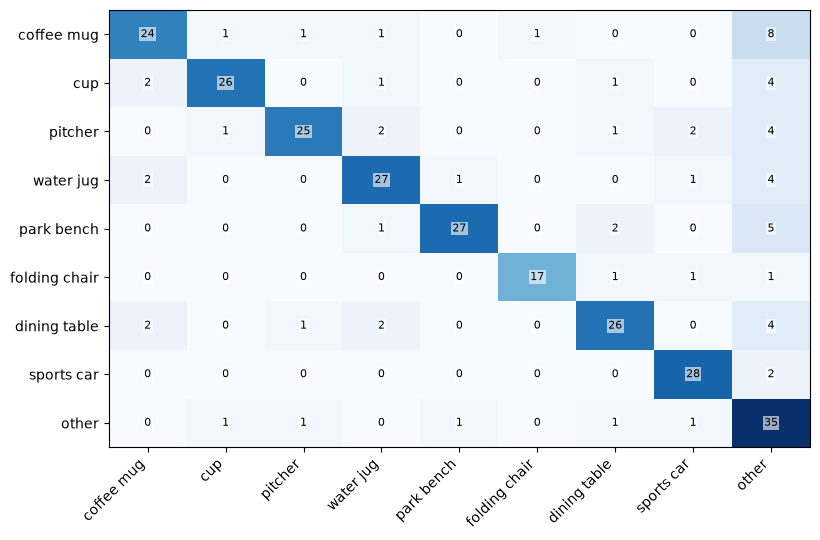

In [27]:
plot_matrix(annotator_confusion(image_ann, "A4", class_names), fmt="d")

O anotador A4 parece ter um viés de rotular imagens como `other`.

## Predições out-of-fold

Passamos agora para o dataset inteiro. Na rodada de produção cada imagem tem um único voto, então
não há concordância para medir. Vamos usar um classificador para apontar os rótulos suspeitos.

As entradas do classificador são os embeddings do DINOv3, e as saídas são os rótulos de
`labels_consensus.csv`, com os erros que eles tiverem.

In [28]:
data = np.load(dataset_dir / "features_dinov3.npz")
image_names = list(data["image_names"])
features = data["features"]

# Normaliza cada vetor para norma 1, como no notebook de embeddings
features = normalize_rows(features)

# Coloca os rótulos na mesma ordem das linhas de features
ordered_consensus = consensus.set_index("image_name").loc[image_names]
labels = ordered_consensus["class_label"].to_numpy()

print(features.shape, labels.shape)

(1845, 384) (1845,)


O `cross_val_predict` faz a validação cruzada e devolve, para cada imagem, a predição do modelo
que **não a viu** no treinamento. Com `method="predict_proba"`, a predição é a probabilidade de
cada classe.

In [56]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict


def out_of_fold_probabilities(features, labels, n_folds=5):
    """Probabilidade de cada classe para cada exemplo, dada por um modelo que não o viu."""
    model = LogisticRegression(max_iter=1000)
    # StratifiedKFold mantém a proporção das classes em cada parte
    folds = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=0)
    return cross_val_predict(model, features, labels, cv=folds, method="predict_proba")


probabilities = out_of_fold_probabilities(features, labels)
predicted = probabilities.argmax(axis=1)

print(probabilities.shape)

(1845, 9)


## Rótulos suspeitos

In [57]:
def find_label_issues(probabilities, labels):
    """Marca os exemplos em que o modelo prefere outra classe com confiança acima do limiar dela."""
    n_classes = probabilities.shape[1]
    rows = np.arange(len(labels))

    # Limiar de cada classe: confiança média do modelo nos exemplos rotulados com ela
    thresholds = np.zeros(n_classes)
    for label in range(n_classes):
        thresholds[label] = probabilities[labels == label, label].mean()

    predicted = probabilities.argmax(axis=1)
    confidence = probabilities[rows, predicted]

    is_suspect = (predicted != labels) & (confidence > thresholds[predicted])
    return is_suspect, thresholds


is_suspect, thresholds = find_label_issues(probabilities, labels)

print(f"modelo discorda do rótulo ... {(predicted != labels).sum()}")
print(f"suspeitos ................... {is_suspect.sum()} de {len(labels)}")
pd.Series(thresholds, index=class_names).round(2)

modelo discorda do rótulo ... 525
suspeitos ................... 294 de 1845


coffee mug       0.40
cup              0.33
pitcher          0.36
water jug        0.30
park bench       0.65
folding chair    0.18
dining table     0.70
sports car       0.49
other            0.42
dtype: float64

Entre os suspeitos, qual era o rótulo dado (linhas) e qual classe o modelo prefere (colunas):

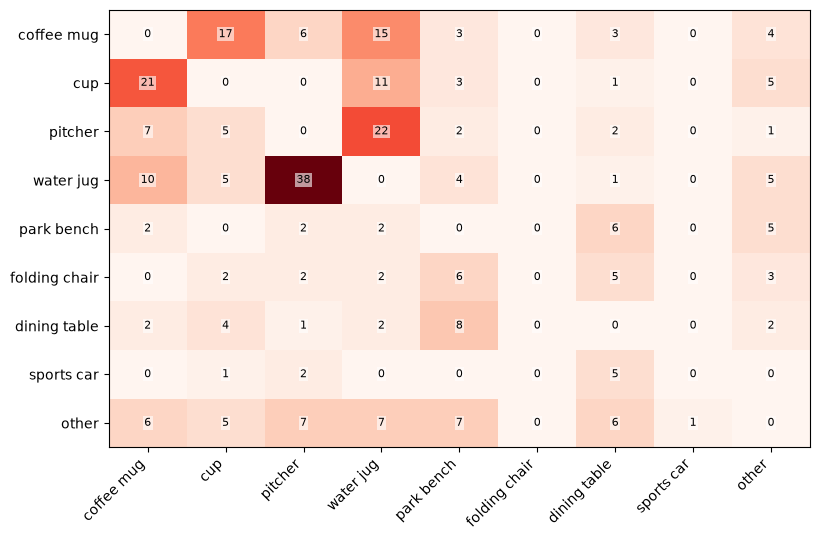

In [60]:
suspect_table = pd.crosstab(labels[is_suspect], predicted[is_suspect])
# Garante que todas as classes aparecem na tabela
suspect_table = suspect_table.reindex(index=range(n_classes), columns=range(n_classes),
                                      fill_value=0)
suspect_table.index = class_names
suspect_table.columns = class_names

plot_matrix(suspect_table, fmt="d", cmap="Reds")

## Ordenar pela margem

A margem compara a probabilidade do rótulo dado com a da melhor classe alternativa.

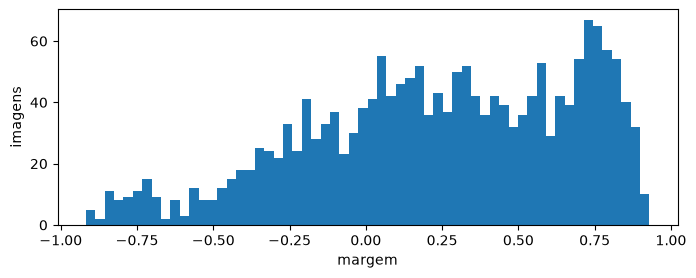

In [61]:
def label_margin(probabilities, labels):
    """Probabilidade do rótulo dado menos a maior probabilidade entre as outras classes."""
    rows = np.arange(len(labels))
    given = probabilities[rows, labels]

    # Zera a coluna do rótulo dado para achar a melhor entre as outras classes
    others = probabilities.copy()
    others[rows, labels] = 0
    best_other = others.max(axis=1)

    return given - best_other


margin = label_margin(probabilities, labels)

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.hist(margin, bins=60)
ax.set_xlabel("margem")
ax.set_ylabel("imagens")
plt.show()